# Expected Threat: fitting and action valuation

**Analytical question:** Value locations and completed movement.

**Stages in this notebook:** Action counts; reward; transition matrix; iterative solution; endpoint gain.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Define labeled actions and states

Start with a transparent synthetic two-state corpus so every count can be checked by hand.

In [4]:
actions=pd.DataFrame([dict(start=0,end=1,kind='move',success=True,goal=False),dict(start=0,end=1,kind='move',success=False,goal=False),dict(start=1,end=1,kind='shot',success=False,goal=True),dict(start=1,end=1,kind='shot',success=False,goal=False)])
display(actions)

,start,end,kind,success,goal
0,0,1,move,True,False
1,0,1,move,False,False
2,1,1,shot,False,True
3,1,1,shot,False,False


## 5. Estimate rewards and successful transitions

Divide counts by all attempted actions from each state. Failed movement has zero continuation in this formulation.

,action_count,immediate_goal_reward
0,2.0,0.0
1,2.0,0.5


,0,1
0,0.0,0.5
1,0.0,0.0


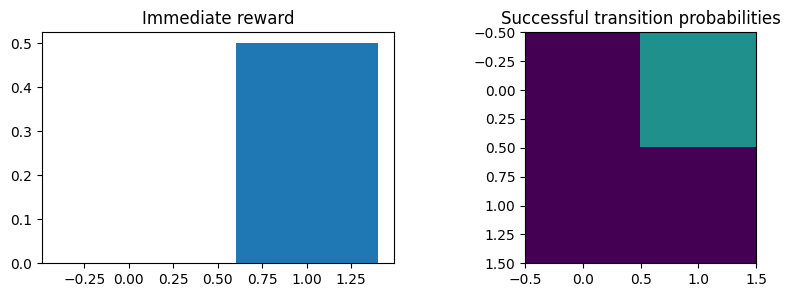

In [5]:
def estimate_xt_components(actions,n_states):
    totals=np.bincount(actions.start,minlength=n_states).astype(float);reward=np.zeros(n_states);transition=np.zeros((n_states,n_states))
    for a in actions.itertuples():
        if a.kind=='shot':reward[a.start]+=float(a.goal)
        elif a.success:transition[a.start,int(a.end)]+=1
    denominator=np.maximum(totals,1)
    return totals,reward/denominator,transition/denominator[:,None]
totals,reward,transition=estimate_xt_components(actions,2)
display(pd.DataFrame({'action_count':totals,'immediate_goal_reward':reward}));display(pd.DataFrame(transition))
fig,axs=plt.subplots(1,2,figsize=(10,3));axs[0].bar(range(2),reward);axs[0].set_title('Immediate reward');axs[1].imshow(transition,vmin=0,vmax=1);axs[1].set_title('Successful transition probabilities');plt.show()

## 6. Inspect value propagation

Follow the iteration from zero values through reward and continuation.

,state 0,state 1
iteration,,
0,0.00,0.0
1,0.00,0.5
2,0.25,0.5
3,0.25,0.5
4,0.25,0.5
5,0.25,0.5
6,0.25,0.5
7,0.25,0.5
8,0.25,0.5


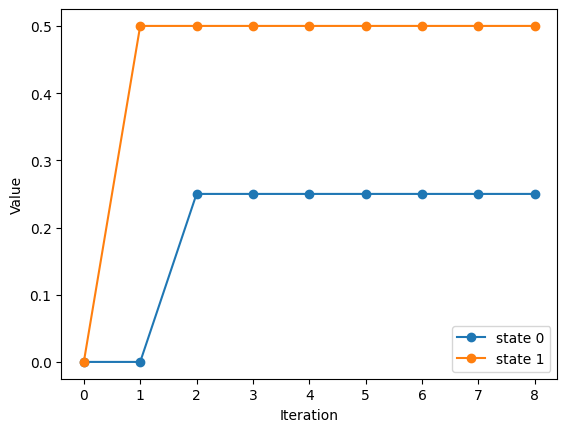

In [6]:
def xt_iterations(transition,reward,steps=8):
    value=np.zeros(len(reward));history=[value.copy()]
    for _ in range(steps):
        continuation=transition@value
        value=reward+continuation;history.append(value.copy())
    return np.array(history)
history=xt_iterations(transition,reward);display(pd.DataFrame(history,columns=['state 0','state 1']).rename_axis('iteration'))
plt.plot(history,'o-');plt.xlabel('Iteration');plt.ylabel('Value');plt.legend(['state 0','state 1']);plt.show()

## 7. Solve to convergence

Package the inspected components and update equation into a reusable fitter.

In [7]:
def fit_xt(actions,n_states,tolerance=1e-10,max_iter=10000):
    totals,reward,transition=estimate_xt_components(actions,n_states);value=np.zeros(n_states)
    for _ in range(max_iter):
        new=reward+transition@value
        if np.max(np.abs(new-value))<tolerance:return new,transition,reward
        value=new
    raise ValueError('No convergence; inspect termination and recurrent states')
values,transition,reward=fit_xt(actions,2);assert np.allclose(values,[.25,.5]);display(pd.Series(values,name='Fitted synthetic xT'))

0    0.25
1    0.50
Name: Fitted synthetic xT, dtype: float64

## 8. Final output: completed-action value gain

Use the values just fitted rather than introducing a separate arbitrary value table.

,start_state,end_state,start_value,end_value,gain
0,0,1,0.25,0.50,0.25
1,1,0,0.50,0.25,-0.25


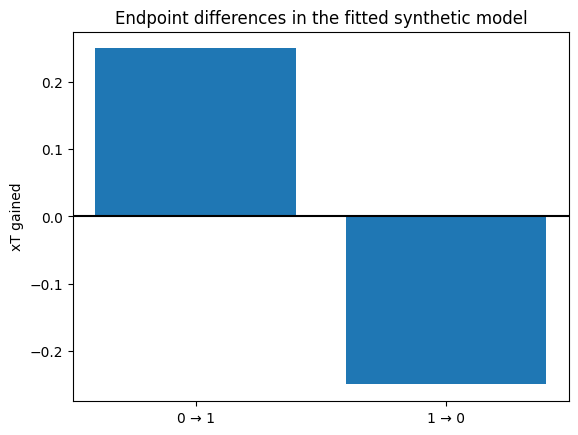

In [8]:
def endpoint_gain(values,start,end):return np.asarray(values)[end]-np.asarray(values)[start]
start=np.array([0,1]);end=np.array([1,0]);gains=endpoint_gain(values,start,end)
display(pd.DataFrame({'start_state':start,'end_state':end,'start_value':values[start],'end_value':values[end],'gain':gains}))
plt.bar(['0 → 1','1 → 0'],gains);plt.axhline(0,c='black');plt.ylabel('xT gained');plt.title('Endpoint differences in the fitted synthetic model');plt.show()

## Interpretation and limitations

This synthetic corpus explains fitting mechanics. A real xT grid needs a complete action corpus, reviewed action conventions and attack normalization. Location-only xT omits defender context. [Karun Singh](https://karun.in/blog/expected-threat.html).